In [2]:
# ============================================================
# Démo PyTorch : apprentissage d'une surface implicite f(x,y,z)=0
# puis visualisation par marching cubes
#
# Dépendances :
# pip install torch numpy matplotlib scikit-image pyvista
# ============================================================

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt
from skimage import measure
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

In [3]:
# ------------------------------------------------------------
# 1. Surface test : sphère ou ellipsoïde
# ------------------------------------------------------------

def implicit_sphere(x, radius=1.0):
    """
    Fonction implicite exacte :
        f(x,y,z) = sqrt(x^2+y^2+z^2) - R
    """
    return np.linalg.norm(x, axis=1) - radius


def implicit_ellipsoid(x, a=1.2, b=0.8, c=0.6):
    """
    Fonction implicite exacte :
        f(x,y,z) = sqrt((x/a)^2+(y/b)^2+(z/c)^2) - 1
    """
    y = np.column_stack([x[:, 0] / a, x[:, 1] / b, x[:, 2] / c])
    return np.linalg.norm(y, axis=1) - 1.0


def sample_sphere_surface(n=3000, radius=1.0):
    u = np.random.rand(n)
    v = np.random.rand(n)

    theta = 2 * np.pi * u
    phi = np.arccos(2 * v - 1)

    x = radius * np.sin(phi) * np.cos(theta)
    y = radius * np.sin(phi) * np.sin(theta)
    z = radius * np.cos(phi)

    return np.column_stack([x, y, z])


def sample_ellipsoid_surface(n=3000, a=1.2, b=0.8, c=0.6):
    pts = sample_sphere_surface(n, radius=1.0)
    pts[:, 0] *= a
    pts[:, 1] *= b
    pts[:, 2] *= c
    return pts

In [4]:
# Choix de la surface
surface_type = "ellipsoid"   # "sphere" ou "ellipsoid"

if surface_type == "sphere":
    surface_points = sample_sphere_surface(n=4000, radius=1.0)
    implicit_exact = lambda x: implicit_sphere(x, radius=1.0)
    box = 1.5
else:
    surface_points = sample_ellipsoid_surface(n=4000, a=1.2, b=0.8, c=0.6)
    implicit_exact = lambda x: implicit_ellipsoid(x, a=1.2, b=0.8, c=0.6)
    box = 1.6


In [5]:
# ------------------------------------------------------------
# 2. Création des données d'entraînement
# ------------------------------------------------------------

n_vol = 20000

# Points aléatoires dans une boîte 3D
X_vol = np.random.uniform(-box, box, size=(n_vol, 3))
y_vol = implicit_exact(X_vol)

# Points exactement sur la surface
X_surf = surface_points
y_surf = np.zeros((len(X_surf),), dtype=np.float32)

# On mélange points volumiques et points de surface
X_train = np.vstack([X_vol, X_surf]).astype(np.float32)
y_train = np.concatenate([y_vol, y_surf]).astype(np.float32)

# Pour éviter des valeurs trop grandes
y_train = np.clip(y_train, -1.0, 1.0)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train[:, None], dtype=torch.float32)


In [6]:
# ------------------------------------------------------------
# 3. Réseau de neurones implicite (pytorch)
# ------------------------------------------------------------

class ImplicitMLP(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x)


model = ImplicitMLP(hidden=128)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

In [7]:
# ------------------------------------------------------------
# 4. Apprentissage
# ------------------------------------------------------------

batch_size = 2048
n_epochs = 2000

N = X_train_t.shape[0]

for epoch in range(n_epochs):
    idx = torch.randint(0, N, (batch_size,))
    xb = X_train_t[idx]
    yb = y_train_t[idx]

    pred = model(xb)
    loss = loss_fn(pred, yb)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 200 == 0:
        print(f"epoch {epoch:5d} | loss = {loss.item():.6e}")


epoch     0 | loss = 4.467026e-01
epoch   200 | loss = 4.597881e-03
epoch   400 | loss = 2.699443e-03
epoch   600 | loss = 2.019659e-03
epoch   800 | loss = 2.055278e-03
epoch  1000 | loss = 1.391669e-03
epoch  1200 | loss = 1.277217e-03
epoch  1400 | loss = 1.149292e-03
epoch  1600 | loss = 1.312467e-03
epoch  1800 | loss = 1.061159e-03


In [8]:
# ------------------------------------------------------------
# 5. Évaluation sur une grille 3D
# ------------------------------------------------------------

grid_res = 64

xs = np.linspace(-box, box, grid_res)
ys = np.linspace(-box, box, grid_res)
zs = np.linspace(-box, box, grid_res)

X, Y, Z = np.meshgrid(xs, ys, zs, indexing="ij")
grid_points = np.column_stack([X.ravel(), Y.ravel(), Z.ravel()]).astype(np.float32)

with torch.no_grad():
    values = model(torch.tensor(grid_points)).cpu().numpy().reshape(
        grid_res, grid_res, grid_res
    )


In [9]:
# ------------------------------------------------------------
# 6. Marching cubes : extraction de f=0
# ------------------------------------------------------------

spacing = (
    xs[1] - xs[0],
    ys[1] - ys[0],
    zs[1] - zs[0],
)

verts, faces, normals, vals = measure.marching_cubes(
    values,
    level=0.0,
    spacing=spacing
)

# marching_cubes donne des coordonnées commençant à 0,
# donc on translate vers [-box, box]^3
verts[:, 0] += xs[0]
verts[:, 1] += ys[0]
verts[:, 2] += zs[0]

In [10]:
# ------------------------------------------------------------
# 7. Visualisation 3D
# ------------------------------------------------------------

%matplotlib ipympl

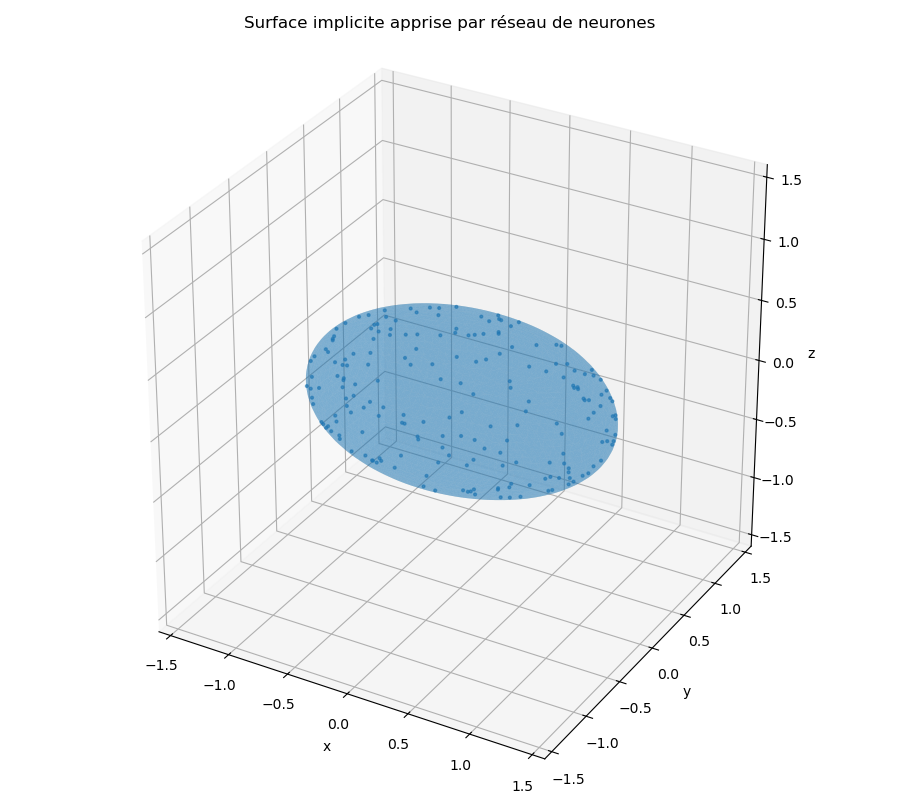

In [11]:
fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111, projection="3d")

mesh = Poly3DCollection(verts[faces], alpha=0.35)
mesh.set_edgecolor("none")
ax.add_collection3d(mesh)

# Points de surface utilisés pour l'apprentissage
ax.scatter(
    surface_points[::20, 0],
    surface_points[::20, 1],
    surface_points[::20, 2],
    s=4,
    alpha=0.6,
)

ax.set_xlim(-box, box)
ax.set_ylim(-box, box)
ax.set_zlim(-box, box)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Surface implicite apprise par réseau de neurones")

ax.set_box_aspect([1, 1, 1])
plt.tight_layout()
plt.show()

In [12]:
#------------------------------------------------------
# Rendu pvista
#------------------------------------------------------

import pyvista as pv
import trimesh

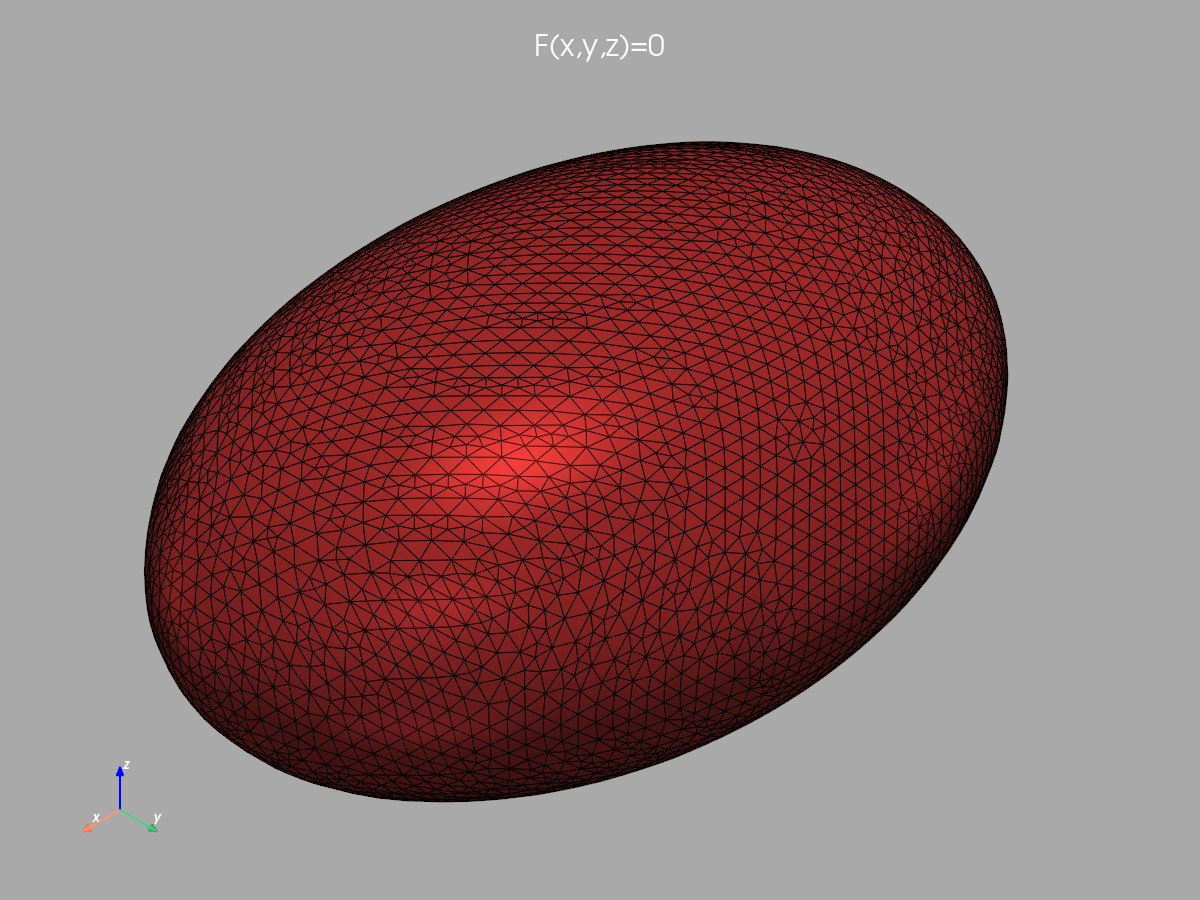

In [13]:
# Format des faces pour PyVista :
# chaque triangle doit être écrit [3, i, j, k]
faces_pv = np.hstack([
    np.full((faces.shape[0], 1), 3),
    faces
]).astype(np.int64)

mesh = pv.PolyData(verts, faces_pv)

# Calcul des normales pour un rendu plus lisse
mesh = mesh.compute_normals(
    point_normals=True,
    cell_normals=True,
    auto_orient_normals=True
)

# Optionnel : lissage léger
mesh_smooth = mesh.smooth(
    n_iter=100,
    relaxation_factor=0.05,
    feature_smoothing=False,
    boundary_smoothing=True
)

# ============================================================
# Visualisation PyVista
# ============================================================

plotter = pv.Plotter(window_size=(1200, 900))

plotter.set_background("darkgrey")

plotter.add_mesh(
    mesh_smooth,
    color="brown",
    smooth_shading=True,
    specular=0.7,
    specular_power=25,
    ambient=0.05,
    opacity = 1.0,
    show_edges=True
)

# Boîte du domaine
#box = pv.Box(bounds=(xmin, xmax, ymin, ymax, zmin, zmax))
#plotter.add_mesh(
#    box,
#    style="wireframe",
#    color="white",
#    opacity=0.35
#)

# Axes
plotter.add_axes(
    xlabel="x",
    ylabel="y",
    zlabel="z",
    line_width=2,
    color="white"
)

plotter.add_title(
    "F(x,y,z)=0",
    font_size=12,
    color="white"
)

# Caméra
plotter.camera_position = "iso"
plotter.camera.zoom(1.5)

plotter.show(jupyter_backend='static')